# 3. Player evaluation

This notebook turns the hold-up model results into **player stats** with the aggregation pipeline (`run_aggregation_pipeline`), then shows the evaluation charts.

## What the aggregation pipeline does

1. **Joins** the event, feature and model-results datasets on `event_id`; keeps hold-ups with a kept / lost outcome.
2. **Hold-up scores**: retention over expected (`roe_c`), set-up added (`setup_c`), duel added (`duel`), value over expected (`voe`, EPV) and raw value added. Set-up added and RoE are centred on the league mean, so the average striker scores 0.
3. **Aggregates per striker with hierarchical shrinkage.** A striker has only a handful of hold-ups, so his raw average is mostly luck. The model treats each striker's true level as drawn from a league-wide distribution and pulls his raw average towards the league mean by as much as the noise warrants: strikers with few hold-ups are pulled the most. How big the real differences between strikers are is *not assumed*; its posterior is computed and every interval includes that uncertainty.
4. **Normalises**: z-scores at hold-up level, and at striker level (shrunk estimates standardised across strikers with at least 10 hold-ups).
5. **Scenarios**: tags each hold-up as difficult pass, high pressure, little support or aerial ball, and repeats the shrinkage inside each scenario.
6. Adds **games played, minutes played** (and minutes his team had the ball), hold-ups per game and **hold-ups per 90** with a gamma-Poisson shrunk rate (this is where minutes played enter the shrinkage).
7. Combines the two into **scores per 90 minutes**: each draw of a striker's level per hold-up is multiplied by a draw of his hold-ups per 90, so a striker who gets more hold-ups per 90 contributes more, and both uncertainties carry into the interval.

All scores are fractions (0.05 = 5 points per 100 hold-ups); charts show points.

In [1]:
import sys
sys.path.insert(0, '../src')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from holdup import aggregate, model
from holdup.pipelines import run_aggregation_pipeline, read_datasets, score_events
from holdup.paths import EVENTS_DIR, FEATURES_DIR, MODEL_PATH
from holdup.plots import z_scatter, forest_plot, scenario_chart, clean_axes, BLUE, ORANGE, GREEN, RED, GREY
pd.set_option('display.width', 170); pd.set_option('display.max_columns', 40)

## 1. Model results for every match

Two sources of model results exist:

* **out of fold** (`data/training/model_results_oof.csv`): each hold-up scored by a model that never saw its match. This is the honest version for the 20 league matches and is what the aggregation uses by default;
* **saved model** (`data/model_results/<match>.csv`, written by `run_event_pipeline(..., use_model=True)`): the model scoring any match, the way a *new* match would be scored. For the training matches this is in-sample.

The cell below scores every match with the saved model from the stored event and feature files and compares the two.

In [2]:
events, features = read_datasets(EVENTS_DIR), read_datasets(FEATURES_DIR)
saved = model.load_model(MODEL_PATH)
results_saved = score_events(events, features, saved)
results_oof = pd.read_csv('../data/training/model_results_oof.csv')
both = results_oof.merge(results_saved, on='event_id', suffixes=('_oof', '_saved')).dropna(subset=['roe_c_oof'])
print(len(both), 'scored hold-ups; correlation of RoE out-of-fold vs saved model:', round(both.roe_c_oof.corr(both.roe_c_saved), 3))
print('mean RoE (centred): out of fold', round(both.roe_c_oof.mean(), 4), ' saved model (in sample)', round(both.roe_c_saved.mean(), 4))

521 scored hold-ups; correlation of RoE out-of-fold vs saved model: 0.999
mean RoE (centred): out of fold 0.0021  saved model (in sample) 0.0004


## 2. Run the aggregation

In [3]:
agg = run_aggregation_pipeline()
scores, players = agg['scores'], agg['player_stats']
SCORES = aggregate.METRICS
print(len(scores), 'scored hold-ups;', scores.key.nunique(), 'strikers;', int(players.rated.sum()), f'with at least {aggregate.MIN_HOLDUPS} hold-ups (rated)')
players[players.rated].sort_values('roe_c_shrunk', ascending=False)[['player', 'team_name', 'games', 'minutes', 'n_holdups', 'holdups_per_game', 'retention', 'service_xr', 'roe_c_raw', 'roe_c_shrunk', 'roe_c_lo', 'roe_c_hi', 'roe_c_pct', 'roe_c_z_shrunk']].round(3).reset_index(drop=True)

521 scored hold-ups; 56 strikers; 21 with at least 10 hold-ups (rated)


,player,team_name,games,minutes,n_holdups,holdups_per_game,retention,service_xr,roe_c_raw,roe_c_shrunk,roe_c_lo,roe_c_hi,roe_c_pct,roe_c_z_shrunk
0,A. Taggart,Perth Glory,1,96.76,11,11.000,0.636,0.323,0.320,0.021,-0.025,0.105,61.158,2.010
1,M. Ruhs,Western United,3,216.46,19,6.333,0.474,0.310,0.170,0.018,-0.029,0.093,61.255,1.602
2,Z. Machach,Melbourne V FC,1,87.83,13,13.000,0.692,0.543,0.155,0.014,-0.035,0.091,59.642,1.255
3,O. Lavale,Western United,3,78.07,13,4.333,0.538,0.375,0.169,0.012,-0.037,0.083,58.388,1.052
4,Z. Sapsford,Western Sydney,2,135.25,10,5.000,0.600,0.454,0.152,0.011,-0.043,0.083,57.980,0.963
5,B. Borrello,Western Sydney,1,79.06,12,12.000,0.750,0.622,0.134,0.010,-0.042,0.072,53.370,0.769
6,A. Kuen,Melbourne City,2,147.63,10,5.000,0.600,0.518,0.088,0.007,-0.046,0.070,51.808,0.532
7,H. Ishige,Wellington P FC,2,177.80,10,5.000,0.500,0.464,0.042,0.006,-0.049,0.066,52.410,0.377
8,M. Mata,Auckland FC,4,238.04,27,6.750,0.296,0.297,0.005,0.003,-0.048,0.058,51.128,0.097
9,T. Waddingham,Brisbane FC,2,173.73,11,5.500,0.364,0.372,-0.002,0.001,-0.053,0.056,50.728,-0.096


## 3. Hold-up level z-scores

Each score standardised across all hold-ups: `z = (score - mean) / sd`. The histograms show how close to a normal curve each score is; value added and value over expected have heavy tails (a few hold-ups that led straight to a chance), so z-scores beyond +/-3 are not unusual for them.

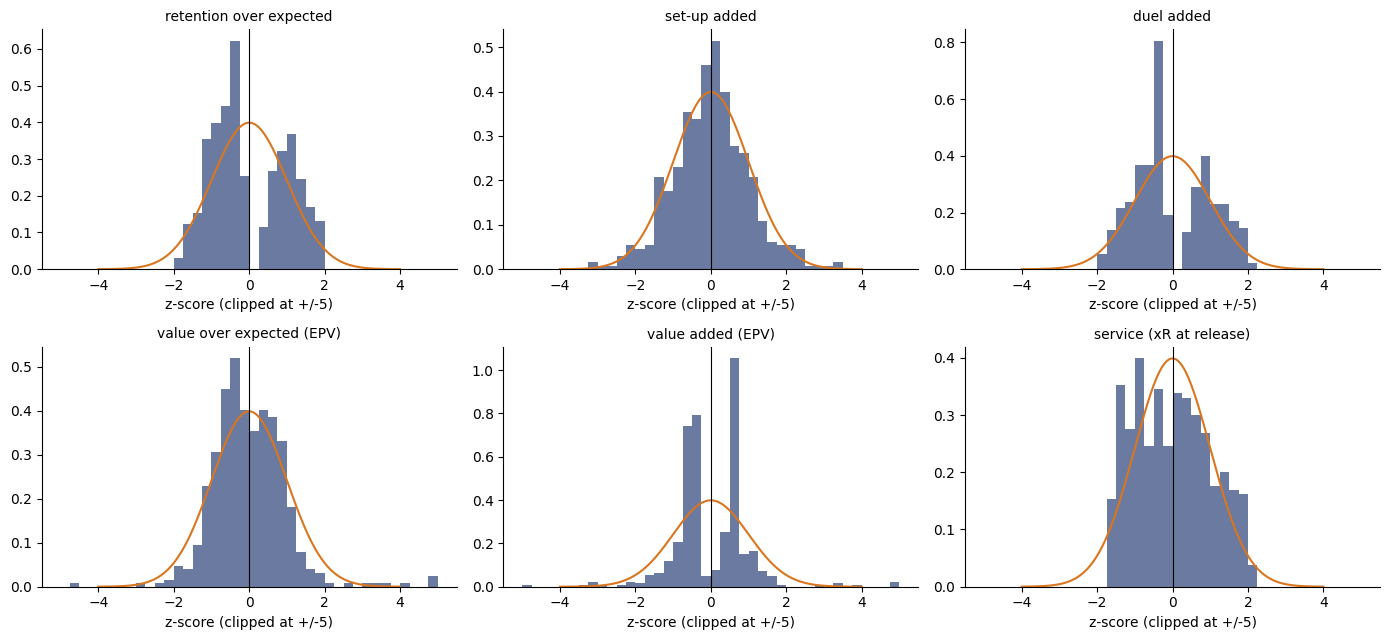

,n,mean,sd,skew,share_beyond_3sd
retention over expected,521.0,0.002,0.458,0.260,0.000
set-up added,521.0,0.000,0.103,0.117,0.010
duel added,521.0,0.002,0.437,0.255,0.000
value over expected (EPV),508.0,-0.000,0.036,1.582,0.015
value added (EPV),508.0,-0.026,0.040,0.759,0.021
service (xR at release),521.0,0.409,0.205,0.219,0.000


In [4]:
zcols = list(SCORES) + ['xr_release']
labels = {**SCORES, 'xr_release': 'service (xR at release)'}
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5)); xs = np.linspace(-4, 4, 200)
for ax, c in zip(axes.ravel(), zcols):
    z = scores['z_' + c].dropna()
    ax.hist(z.clip(-5, 5), bins=np.linspace(-5, 5, 41), density=True, color=BLUE, alpha=.75)
    ax.plot(xs, stats.norm.pdf(xs), c=ORANGE, lw=1.5); ax.axvline(0, c='k', lw=.8)
    ax.set_title(labels[c], fontsize=10); ax.set_xlabel('z-score (clipped at +/-5)'); clean_axes(ax)
plt.tight_layout(); plt.show()
pd.DataFrame({labels[c]: dict(n=int(scores[c].notna().sum()), mean=scores[c].mean(), sd=scores[c].std(), skew=stats.skew(scores[c].dropna()),
              share_beyond_3sd=(scores['z_' + c].abs() > 3).mean()) for c in zcols}).T.round(3)

## 4. How much of the difference between strikers is real?

The **intra-class correlation (ICC)** is the share of the variance in single hold-ups that is a real, repeatable striker difference. Values near 0 mean that at this sample size almost everything we see in a striker's average is luck, which is why his estimate is pulled hard towards the league mean. The 95th percentile shows how large the real spread could plausibly be.

In [5]:
rows = []
for c, lab in SCORES.items():
    s = aggregate.between_spread(scores.dropna(subset=[c]), c)
    rows.append(dict(score=lab, strikers=s['n_strikers'], hold_ups=s['n_holdups'], sd_one_holdup_pts=s['sd_within'] * 100,
                     real_sd_between_median_pts=s['sd_between_median'] * 100, real_sd_between_p95_pts=s['sd_between_p95'] * 100,
                     icc_median=s['icc_median'], icc_p95=s['icc_p95']))
pd.DataFrame(rows).set_index('score').round(3)

,strikers,hold_ups,sd_one_holdup_pts,real_sd_between_median_pts,real_sd_between_p95_pts,icc_median,icc_p95
score,,,,,,,
retention over expected,56,521,46.208,2.550,7.650,0.003,0.027
set-up added,56,521,10.241,0.713,2.014,0.005,0.037
duel added,56,521,44.226,2.285,6.855,0.003,0.023
value over expected (EPV),56,508,3.561,0.504,1.022,0.020,0.076
value added (EPV),56,508,3.921,0.467,1.012,0.014,0.062


### The shrinkage formula

For striker $j$ with $n_j$ hold-ups and raw average $\bar y_j$ of a score (RoE, set-up, duel, ...), let

* $\mu$ = the league mean of the score (average over all hold-ups),
* $\sigma_w$ = the standard deviation of a *single* hold-up around its striker's own average (pooled over strikers),
* $\tau$ = the real standard deviation *between* strikers' true levels.

The model is

$$\bar y_j \sim \mathrm{Normal}\!\left(\theta_j,\ \frac{\sigma_w^2}{n_j}\right), \qquad \theta_j \sim \mathrm{Normal}(\mu,\ \tau^2)$$

where $\theta_j$ is his true level. Given $\tau$, the estimate of $\theta_j$ is a weighted average of his own average and the league mean:

$$\hat\theta_j = \mu + B_j\,(\bar y_j - \mu), \qquad B_j = \frac{\tau^2}{\tau^2 + \sigma_w^2 / n_j}$$

$B_j$ is the share of his own average that is kept: near 1 with many hold-ups or a large real spread, near 0 with few hold-ups or a tiny real spread. The uncertainty left after shrinking is

$$\mathrm{Var}(\theta_j \mid \bar y_j) = B_j\,\frac{\sigma_w^2}{n_j}$$

so the interval is narrower than the raw one by exactly the factor $B_j$ in variance.

**$\tau$ is not assumed.** Its posterior is computed on a grid of 300 values from 0 to $2\,\mathrm{sd}(\bar y_j)$ with a flat prior, from the likelihood

$$\bar y_j \sim \mathrm{Normal}\!\left(\mu,\ \tau^2 + \frac{\sigma_w^2}{n_j}\right)$$

Each of the 2,000 draws samples a $\tau$ from that posterior, computes $B_j$ and draws

$$\theta_j^{(d)} = \mu + B_j^{(d)}(\bar y_j - \mu) + \varepsilon, \qquad \varepsilon \sim \mathrm{Normal}\!\left(0,\ B_j^{(d)}\,\sigma_w^2 / n_j\right)$$

The **shrunk estimate** is the mean of the draws, the **90% interval** their 5th and 95th percentiles, **P(above league)** the share of draws above $\mu$, and the **percentile** the striker's rank among rated strikers within each draw (so it carries a range).

The share of single-hold-up variance that is a real, repeatable striker difference is the intra-class correlation

$$\mathrm{ICC} = \frac{\tau^2}{\tau^2 + \sigma_w^2}$$

**Z-scores** standardise the shrunk estimates across the rated strikers (at least 10 hold-ups): $z_j = (\hat\theta_j - \overline{\hat\theta}) / \mathrm{sd}(\hat\theta)$, with the interval ends on the same scale. Because the shrunk estimates are compressed towards $\mu$, their sd is small and the intervals are several z-scores wide.

**Minutes played enter through the hold-up rate.** Hold-ups per 90 use a gamma-Poisson model: count $\sim \mathrm{Poisson}(\lambda\,\text{minutes})$ with $\lambda \sim \mathrm{Gamma}(a, b)$, $(a, b)$ fitted to all strikers, giving the posterior $\lambda_j \mid \text{data} \sim \mathrm{Gamma}(a + \text{count}_j,\ b + \text{minutes}_j)$. A striker with 6 hold-ups in 100 minutes is pulled towards the league rate more than one with 20 in 800.

**Scores per 90 minutes.** A striker's total contribution is his level per hold-up times his hold-ups per 90. For each of the 2,000 draws, $\theta_j^{(d)}$ (above) is multiplied by an independent draw $90\,\lambda_j^{(d)}$ from his rate posterior:

$$\text{score per 90}_j^{(d)} = \theta_j^{(d)} \times 90\,\lambda_j^{(d)}$$

The estimate is the mean of these draws, the interval their 5th and 95th percentiles, and the league reference is $\mu \times$ the league hold-up rate per 90. Units are the score's own units per 90 minutes: extra kept hold-ups per 90 for RoE, set-up and duel, EPV per 90 for value over expected.

In the code this is `striker_posterior` and `between_spread` in `src/holdup/aggregate.py`.

## 5. Shrunk estimates with 90% intervals

Each striker's **shrunk estimate** (filled dot), 90% interval (bar) and raw average (open dot). The black line is the league mean. Where no interval clears the league mean, the data cannot separate that striker from average.

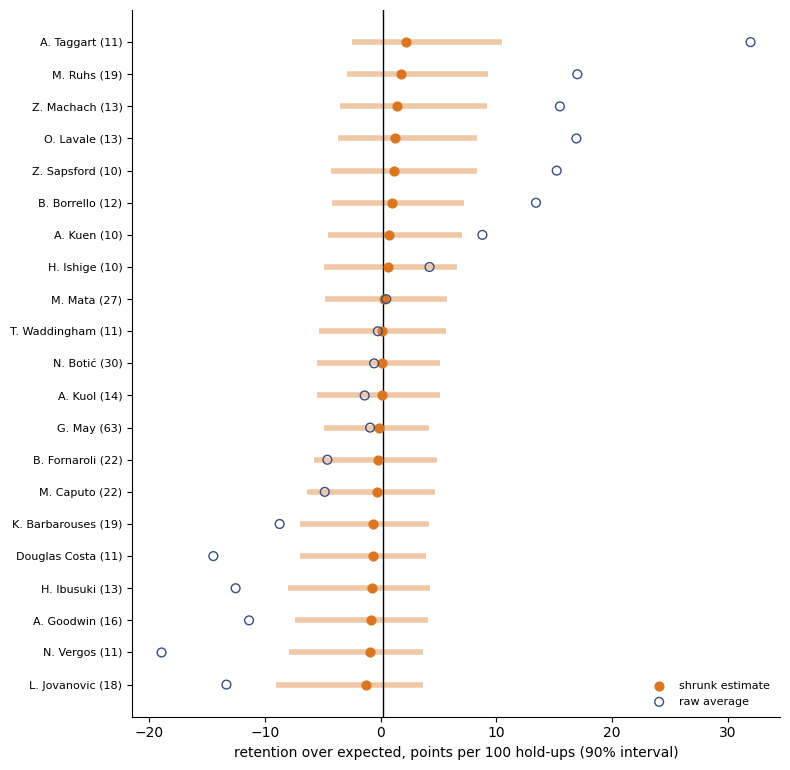

In [6]:
forest_plot(players, 'roe_c', 'retention over expected')

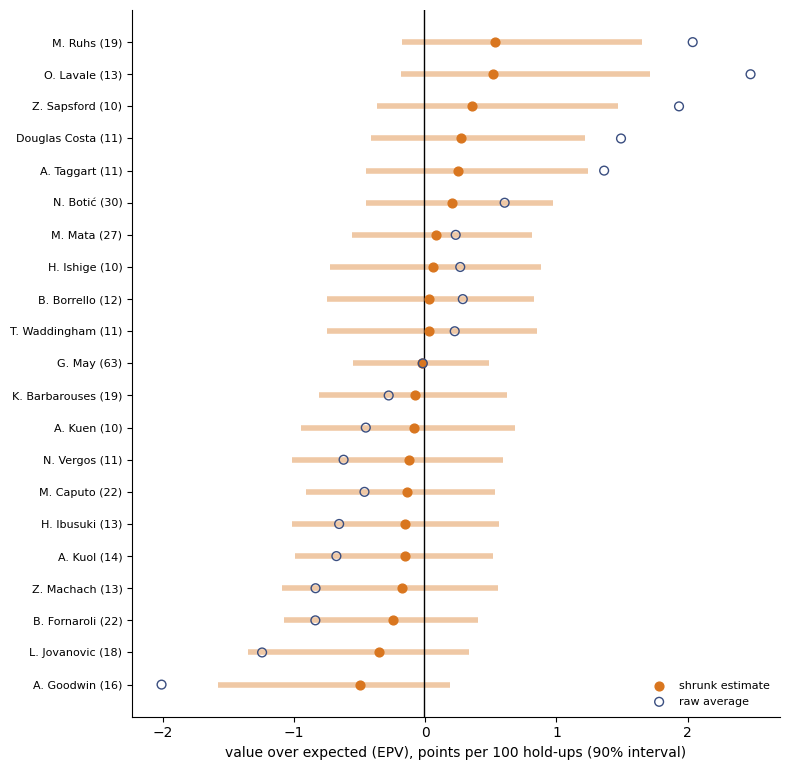

In [7]:
forest_plot(players, 'voe', 'value over expected (EPV)')

In [8]:
tab = players[players.rated].copy()
summary = []
for c, lab in SCORES.items():
    t = tab[tab[c + '_shrunk'].notna()]
    summary.append(dict(score=lab, rated_strikers=len(t), shrunk_range_pts=f"{t[c + '_shrunk'].min() * 100:+.1f} to {t[c + '_shrunk'].max() * 100:+.1f}",
                        interval_excludes_league=int(((t[c + '_lo'] > t[c + '_league_mean']) | (t[c + '_hi'] < t[c + '_league_mean'])).sum()),
                        max_p_above_league=t[c + '_p_above_league'].max(), percentile_range_width_median=(t[c + '_pct_hi'] - t[c + '_pct_lo']).median()))
pd.DataFrame(summary).set_index('score').round(2)

,rated_strikers,shrunk_range_pts,interval_excludes_league,max_p_above_league,percentile_range_width_median
score,,,,,
retention over expected,21,-1.2 to +2.1,0,0.65,95.0
set-up added,21,-0.4 to +0.5,0,0.64,95.0
duel added,21,-1.0 to +1.7,0,0.63,95.0
value over expected (EPV),21,-0.5 to +0.5,0,0.82,90.0
value added (EPV),21,-3.0 to -2.2,0,0.78,90.0


## 6. Set-up added vs duel added (z-scores)

Each dot is a rated striker. **Right** = adds value through movement before the ball arrives (the mover); **up** = wins the situation once the ball arrives (the duel winner). The orange cross in the corner is a typical 90% interval: intervals are several z-scores wide, so positions on the chart are far less certain than they look.

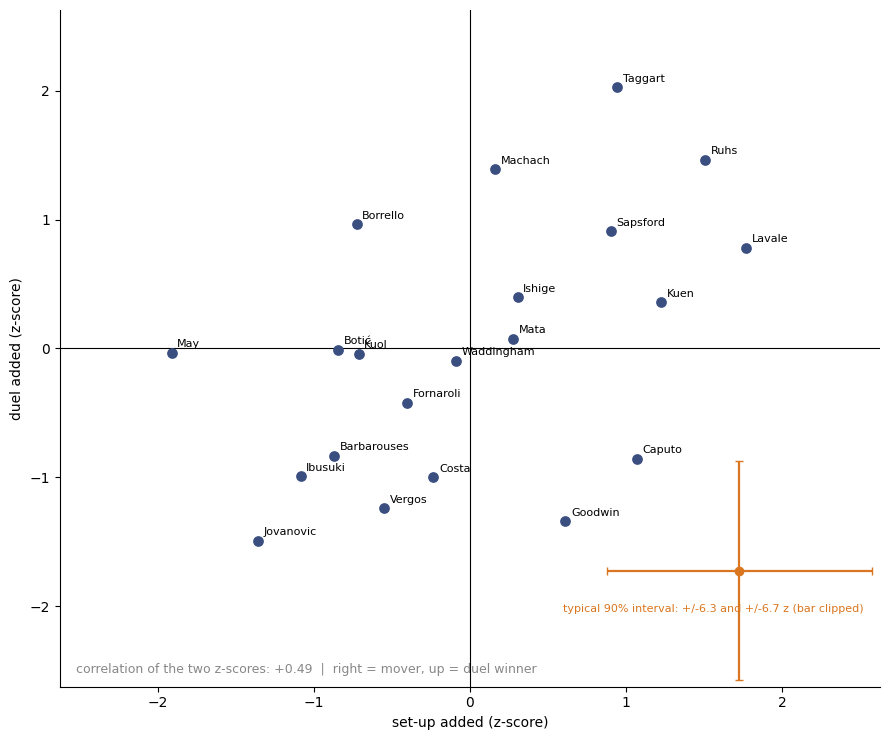

In [9]:
r1 = z_scatter(players, 'setup_c', 'duel', 'set-up added (z-score)', 'duel added (z-score)', BLUE, 'right = mover, up = duel winner')

## 7. Retention over expected vs value over expected (z-scores)

**Right** = keeps the ball more than expected; **up** = creates more EPV than expected from the situation. A striker can keep the ball often and still add little value if he lays it back; the other way round, a striker who loses it more often but turns it forward would sit high and to the left.

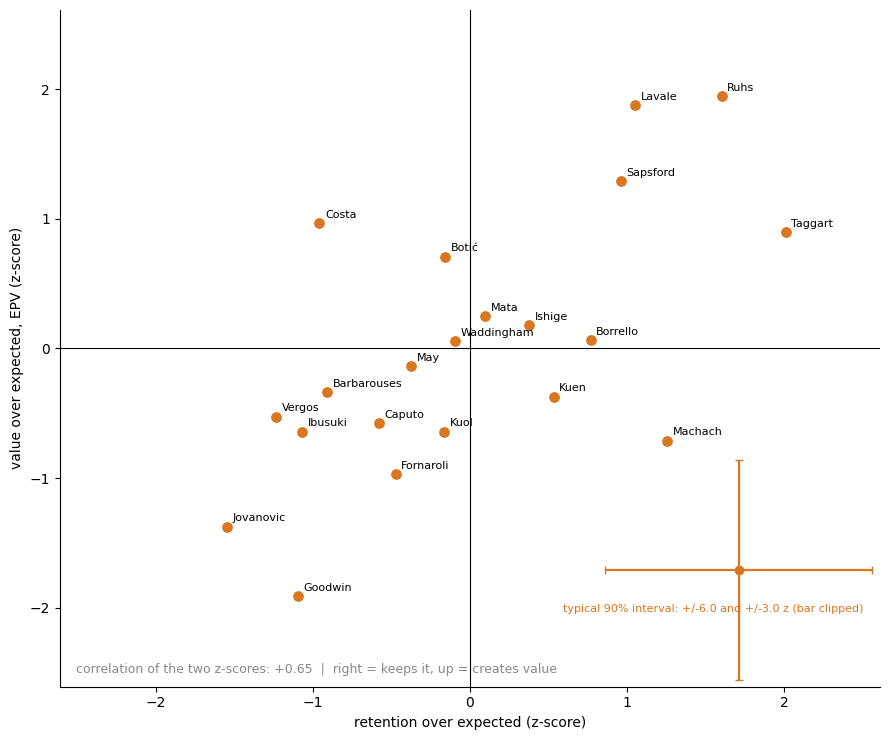

z(RoE) vs z(set-up) / z(duel): see charts; z(RoE) vs z(raw EPV value added): +0.53; z(RoE) vs z(EPV over expected): +0.65; z(set-up) vs z(duel): +0.49


In [10]:
r2 = z_scatter(players, 'roe_c', 'voe', 'retention over expected (z-score)', 'value over expected, EPV (z-score)', ORANGE, 'right = keeps it, up = creates value')
r3 = players[players.rated][['roe_c_z_shrunk', 'value_added_z_shrunk']].corr().iloc[0, 1]
print(f"z(RoE) vs z(set-up) / z(duel): see charts; z(RoE) vs z(raw EPV value added): {r3:+.2f}; z(RoE) vs z(EPV over expected): {r2:+.2f}; z(set-up) vs z(duel): {r1:+.2f}")

## 8. Scenarios: retention over expected when the situation is hard

Overall RoE already adjusts for how hard the situation was, but a coach also wants to know how a striker does *specifically* in a hard situation. Each hold-up is tagged with the scenarios it falls in:

| Scenario | Rule (the hard side) |
| --- | --- |
| Difficult passes | lowest third of expected pass completion |
| High pressure | oval pressure at first contact of 0.59 or more (about the top third) |
| Little support | at most one team-mate he could pass to with at least a 60% completion chance |
| Aerial balls | the pass into him is an aerial ball |

A hold-up can be in several scenarios at once.

In [11]:
thr = agg['thresholds'].copy()
tags = agg['scenario_tags']
rows = [dict(scenario='All hold-ups', rule='-', hold_ups=len(scores), share=1.0, kept=scores.retained.mean(), xr_release=scores.xr_release.mean(), roe_pts=scores.roe_c.mean() * 100, setup_pts=scores.setup_c.mean() * 100, duel_pts=scores.duel.mean() * 100)]
for name, rule in aggregate.SCENARIOS.items():
    q = scores[tags[name]]
    rows.append(dict(scenario=name, rule=f"{rule['column']} {'>=' if rule['hard'] == 'high' else '<='} {thr.loc[name, 'cut_off']:.2f}", hold_ups=len(q), share=len(q) / len(scores),
                     kept=q.retained.mean(), xr_release=q.xr_release.mean(), roe_pts=q.roe_c.mean() * 100, setup_pts=q.setup_c.mean() * 100, duel_pts=q.duel.mean() * 100))
pd.DataFrame(rows).set_index('scenario').round(3)

,rule,hold_ups,share,kept,xr_release,roe_pts,setup_pts,duel_pts
scenario,,,,,,,,
All hold-ups,-,521,1.000,0.405,0.409,0.210,0.000,0.210
Difficult passes,xpass <= 0.62,173,0.332,0.214,0.241,-2.103,-1.292,-0.812
High pressure,con_oval_sum >= 0.59,172,0.330,0.390,0.361,3.466,0.559,2.907
Little support,sup_n_xp60 <= 1.00,183,0.351,0.279,0.324,-3.961,-2.404,-1.557
Aerial balls,aerial >= 1.00,226,0.434,0.212,0.236,-1.761,-1.782,0.021


In [12]:
print('overlap (hold-ups in both scenarios):')
pd.DataFrame({a: {b: int((tags[a] & tags[b]).sum()) for b in tags} for a in tags})

overlap (hold-ups in both scenarios):


,Difficult passes,High pressure,Little support,Aerial balls
Difficult passes,173,62,71,145
High pressure,62,172,59,70
Little support,71,59,183,102
Aerial balls,145,70,102,226


### Other rule sets and the share of hold-ups they cover

For each scenario, alternative ways to draw the line, with the share of all hold-ups each applies to, how often the striker kept the ball, the average RoE, and how many strikers have at least 5 hold-ups in it. To use one, copy its column, direction and cut-off into `SCENARIOS` in `src/holdup/aggregate.py`.

In [13]:
RULES = [   # (scenario, description, column, which side is hard, ('q', quantile) or ('v', value))
    ('Difficult passes', 'expected completion, lowest quarter', 'xpass', 'low', ('q', .25)),
    ('Difficult passes', 'expected completion, lowest third', 'xpass', 'low', ('q', 1 / 3)),
    ('Difficult passes', 'expected completion, lowest 40%', 'xpass', 'low', ('q', .40)),
    ('Difficult passes', 'expected completion at most 50%', 'xpass', 'low', ('v', .5)),
    ('Difficult passes', 'expected completion at most 60%', 'xpass', 'low', ('v', .6)),
    ('Difficult passes', 'ball peaks in the highest third', 'peak_height', 'high', ('q', 2 / 3)),
    ('Difficult passes', 'xR at release in the lowest third', 'xr_release', 'low', ('q', 1 / 3)),
    ('Difficult passes', 'pass distance in the longest third', 'pass_distance', 'high', ('q', 2 / 3)),
    ('High pressure', 'oval pressure, top half', 'con_oval_sum', 'high', ('q', .5)),
    ('High pressure', 'oval pressure, top third (0.59 or more)', 'con_oval_sum', 'high', ('v', .59)),
    ('High pressure', 'oval pressure, top quarter', 'con_oval_sum', 'high', ('q', .75)),
    ('High pressure', '2 or more defenders within 5 m', 'con_n5', 'high', ('v', 2)),
    ('High pressure', '3 or more defenders within 5 m', 'con_n5', 'high', ('v', 3)),
    ('Little support', 'no team-mate at 60%+', 'sup_n_xp60', 'low', ('v', 0)),
    ('Little support', 'at most 1 team-mate at 60%+', 'sup_n_xp60', 'low', ('v', 1)),
    ('Little support', 'at most 2 team-mates at 60%+', 'sup_n_xp60', 'low', ('v', 2)),
    ('Little support', 'no open passing lane', 'sup_n_lane_open', 'low', ('v', 0)),
    ('Little support', 'at most 1 open passing lane', 'sup_n_lane_open', 'low', ('v', 1)),
    ('Aerial balls', 'ball flagged aerial', 'aerial', 'high', ('v', 1)),
    ('Aerial balls', 'ball peaks above 2 m', 'peak_height', 'high', ('v', 2.0)),
    ('Aerial balls', 'ball peaks above 3 m', 'peak_height', 'high', ('v', 3.0)),
]
rows = []
for scen, desc, col, hard, (kind, val) in RULES:
    cut = scores[col].quantile(val) if kind == 'q' else val
    inside = (scores[col] >= cut) if hard == 'high' else (scores[col] <= cut)
    q = scores[inside]; cur = aggregate.SCENARIOS[scen]
    in_use = cur['column'] == col and cur['hard'] == hard and abs(thr.loc[scen, 'cut_off'] - float(cut)) < 1e-9
    rows.append(dict(scenario=scen, rule=desc + ('   <- in use' if in_use else ''), cut_off=round(float(cut), 3), hold_ups=int(inside.sum()), pct_of_hold_ups=round(100 * inside.mean(), 1),
                     kept_pct=round(100 * q.retained.mean(), 1), roe_pts=round(100 * q.roe_c.mean(), 1), strikers_with_5plus=int((q.groupby('key').size() >= 5).sum())))
pd.set_option('display.max_colwidth', 70)
pd.DataFrame(rows).set_index(['scenario', 'rule'])

cut_off  hold_ups  pct_of_hold_ups  kept_pct  roe_pts  strikers_with_5plus
scenario         rule                                                                                                                           
Difficult passes expected completion, lowest quarter                    0.485       130             25.0      21.5     -0.6                    9
                 expected completion, lowest third   <- in use          0.615       173             33.2      21.4     -2.1                   10
                 expected completion, lowest 40%                        0.675       207             39.7      22.7     -2.2                   14
                 expected completion at most 50%                        0.500       136             26.1      21.3     -0.8                   10
                 expected completion at most 60%                        0.600       167             32.1      21.6     -1.6                   10
                 ball peaks in the highest third                        3.140       175             33.6      16.6     -3.7                   12
                 xR at release in the lowest third                      0.284       174             33.4      17.8      0.5                   13
                 pass distance in the longest third                    20.704       174             33.4      28.2     -0.6                   12
High pressure    oval pressure, top half                                0.450       261             50.1      37.9      0.5                   19
                 oval pressure, top third (0.59 or more)   <- in use    0.590       172             33.0      39.0      3.5                   12
                 oval pressure, top quarter                             0.653       131             25.1      39.7      5.0                    9
                 2 or more defenders within 5 m                         2.000       185             35.5      35.1     -2.6                   13
                 3 or more defenders within 5 m                         3.000        34              6.5      17.6    -19.0                    0
Little support   no team-mate at 60%+                                   0.000        45              8.6      20.0    -10.9                    2
                 at most 1 team-mate at 60%+   <- in use                1.000       183             35.1      27.9     -4.0                   14
                 at most 2 team-mates at 60%+                           2.000       338             64.9      32.8     -2.5                   25
                 no open passing lane                                   0.000       196             37.6      33.2     -3.0                   16
                 at most 1 open passing lane                            1.000       259             49.7      34.0     -2.4                   22
Aerial balls     ball flagged aerial   <- in use                        1.000       226             43.4      21.2     -1.8                   14
                 ball peaks above 2 m                                   2.000       220             42.2      20.0     -2.7                   13
                 ball peaks above 3 m                                   3.000       185             35.5      17.3     -3.6                   12

### Shrinkage inside each scenario

Within a scenario a striker has few hold-ups (often under 10), so his raw RoE there is mostly luck. The same hierarchical model is fitted **inside each scenario**: his estimate is pulled towards the league average *for that scenario* (the black tick). First, how large the real differences between strikers are in each scenario:

In [14]:
spread = agg['scenario_spread'].copy()
spread[['league_mean', 'sd_between_median', 'sd_between_p95', 'sd_within']] *= 100
spread.rename(columns={'league_mean': 'scenario_mean_pts', 'sd_between_median': 'real_sd_median_pts', 'sd_between_p95': 'real_sd_p95_pts', 'sd_within': 'sd_one_holdup_pts'})[
    ['n_strikers', 'n_holdups', 'scenario_mean_pts', 'real_sd_median_pts', 'real_sd_p95_pts', 'sd_one_holdup_pts', 'icc_median', 'icc_p95']].round(3)

,n_strikers,n_holdups,scenario_mean_pts,real_sd_median_pts,real_sd_p95_pts,sd_one_holdup_pts,icc_median,icc_p95
scenario,,,,,,,,
All hold-ups,56,521,0.210,2.550,7.650,46.208,0.003,0.027
Difficult passes,47,173,-2.103,6.007,15.661,39.289,0.023,0.137
High pressure,46,172,3.466,10.599,20.972,44.047,0.055,0.185
Little support,46,183,-3.961,4.995,14.151,44.474,0.012,0.092
Aerial balls,50,226,-1.761,5.441,13.811,39.761,0.018,0.108


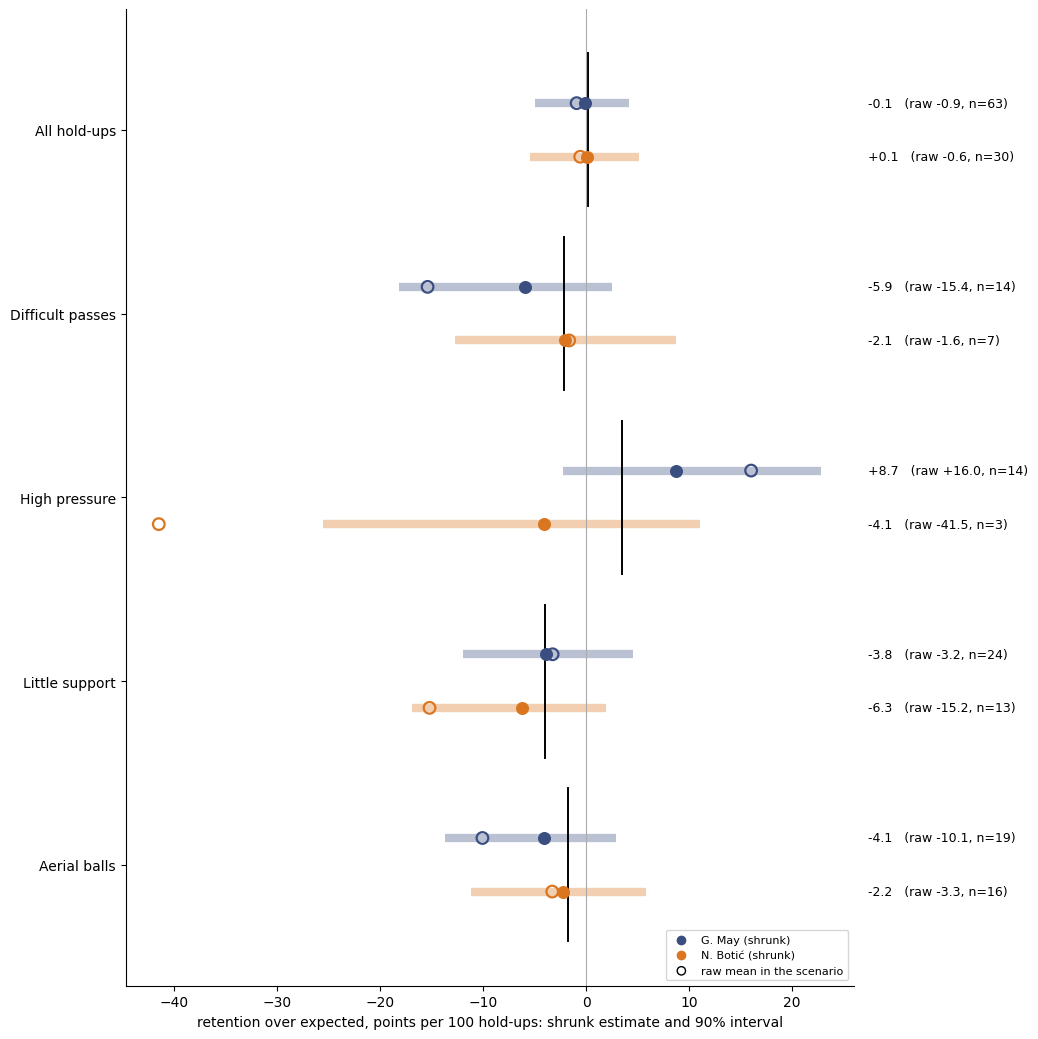

In [15]:
sp = agg['scenario_players']
by_n = players.sort_values('n_holdups', ascending=False)
pair = list(by_n.key.head(2))          # the two strikers with the most hold-ups; change to any two keys, e.g. 'May | Brisbane Roar'
scenario_chart(sp, pair)

In [16]:
rows = []
for name in aggregate.SCENARIOS:
    t = sp[(sp.scenario == name) & (sp.n >= 5)]
    mu = t.scenario_mean.iloc[0] if len(t) else np.nan
    rows.append(dict(scenario=name, strikers_with_5plus=len(t), raw_range_pts=f"{t.raw.min() * 100:+.0f} to {t.raw.max() * 100:+.0f}" if len(t) else '-',
                     shrunk_range_pts=f"{t.shrunk.min() * 100:+.1f} to {t.shrunk.max() * 100:+.1f}" if len(t) else '-',
                     interval_excludes_scenario_mean=int(((t.lo > mu) | (t.hi < mu)).sum()), max_p_above=t.p_above_scenario_mean.max() if len(t) else np.nan))
pd.DataFrame(rows).set_index('scenario').round(2)

,strikers_with_5plus,raw_range_pts,shrunk_range_pts,interval_excludes_scenario_mean,max_p_above
scenario,,,,,
Difficult passes,10,-29 to +10,-7.1 to +0.7,0,0.64
High pressure,12,-33 to +32,-7.2 to +10.1,0,0.73
Little support,14,-29 to +39,-6.8 to +0.9,0,0.70
Aerial balls,14,-25 to +21,-5.1 to +2.2,0,0.72


## 9. Scores per 90 minutes

Per-hold-up scores say how good a striker is *when he gets a hold-up*; multiplying by how often he gets one (shrunk hold-ups per 90, from minutes played) gives his total contribution per 90 minutes. The chart shows the retention-over-expected version: extra kept hold-ups per 90 minutes, with the 90% interval from combining both uncertainties.

,player,team_name,games,minutes,n_holdups,holdups_per90_shrunk,roe_c_shrunk,roe_c_per90,roe_c_per90_lo,roe_c_per90_hi,roe_c_per90_p_above_league,voe_per90
0,A. Taggart,Perth Glory,1,96.76,11,8.372,0.021,0.181,-0.219,0.853,0.688,0.021
1,Z. Machach,Melbourne V FC,1,87.83,13,9.584,0.014,0.135,-0.340,0.850,0.642,-0.017
2,M. Ruhs,Western United,3,216.46,19,7.539,0.018,0.134,-0.209,0.724,0.649,0.040
3,O. Lavale,Western United,3,78.07,13,10.051,0.012,0.125,-0.374,0.851,0.630,0.052
4,B. Borrello,Western Sydney,1,79.06,12,9.554,0.010,0.088,-0.385,0.711,0.605,0.003
5,Z. Sapsford,Western Sydney,2,135.25,10,6.771,0.011,0.078,-0.269,0.576,0.589,0.024
6,A. Kuen,Melbourne City,2,147.63,10,6.461,0.007,0.048,-0.311,0.463,0.538,-0.006
7,H. Ishige,Wellington P FC,2,177.80,10,5.812,0.006,0.035,-0.285,0.387,0.518,0.004
8,M. Mata,Auckland FC,4,238.04,27,9.086,0.003,0.029,-0.436,0.485,0.542,0.008
9,T. Waddingham,Brisbane FC,2,173.73,11,6.195,0.001,0.008,-0.333,0.362,0.477,0.002


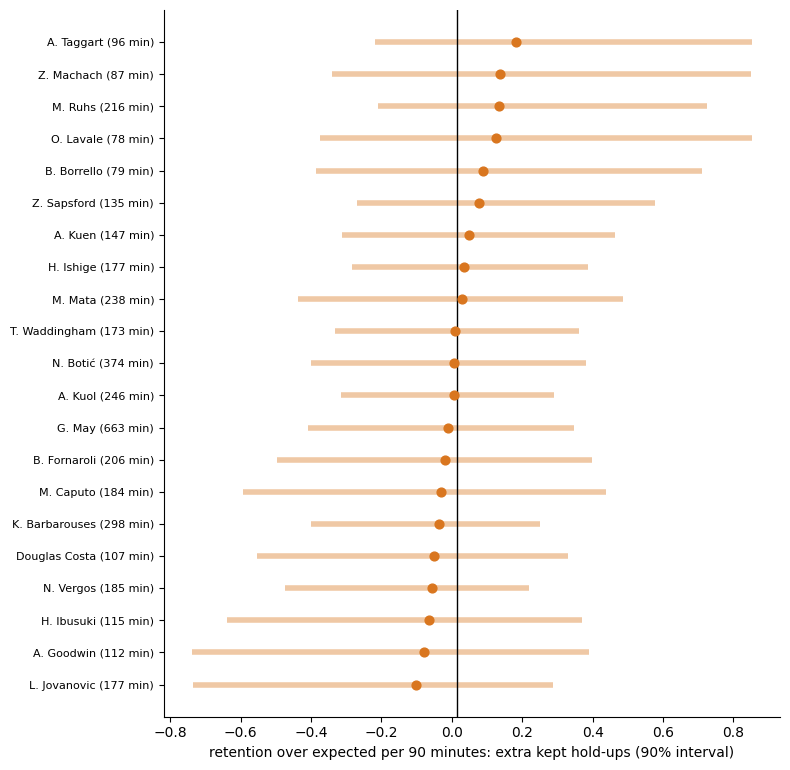

In [17]:
t = players[players.rated].copy()
cols = ['player', 'team_name', 'games', 'minutes', 'n_holdups', 'holdups_per90_shrunk', 'roe_c_shrunk', 'roe_c_per90', 'roe_c_per90_lo', 'roe_c_per90_hi', 'roe_c_per90_p_above_league', 'voe_per90']
display(t.sort_values('roe_c_per90', ascending=False)[cols].round(3).reset_index(drop=True))
t = t.sort_values('roe_c_per90'); y = np.arange(len(t))
fig, ax = plt.subplots(figsize=(8, 0.3 * len(t) + 1.5))
ax.hlines(y, t.roe_c_per90_lo, t.roe_c_per90_hi, color=ORANGE, lw=4, alpha=.4); ax.scatter(t.roe_c_per90, y, c=ORANGE, s=40, zorder=3)
ax.axvline(t.roe_c_league_per90.iloc[0], c='k', lw=1); ax.set_yticks(y); ax.set_yticklabels([f'{p} ({int(m)} min)' for p, m in zip(t.player, t.minutes)], fontsize=8)
ax.set_xlabel('retention over expected per 90 minutes: extra kept hold-ups (90% interval)'); clean_axes(ax); plt.tight_layout(); plt.show()

## 10. How often does each striker get a hold-up?

Hold-ups per 90 minutes played, shrunk towards the league rate with a gamma-Poisson model (a striker with 6 hold-ups in 100 minutes is pulled towards the league rate more than one with 20 in 800).

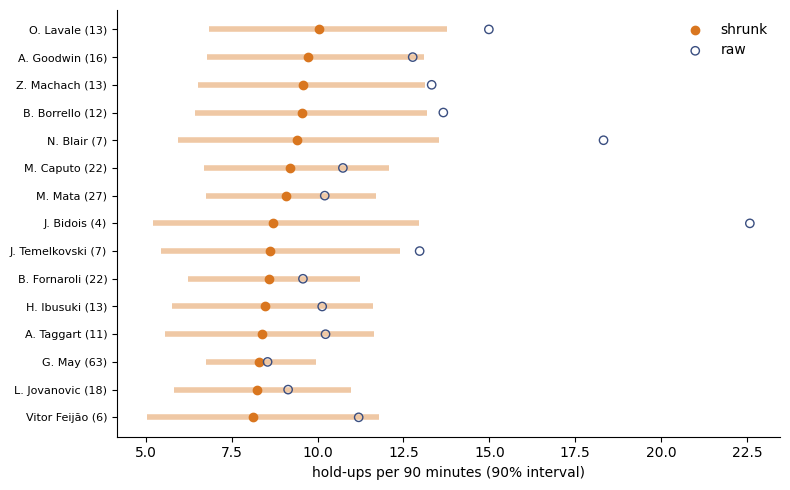

In [18]:
r = players.sort_values('holdups_per90_shrunk', ascending=False).head(15)
fig, ax = plt.subplots(figsize=(8, 5)); y = np.arange(len(r))[::-1]
ax.hlines(y, r.holdups_per90_lo, r.holdups_per90_hi, color=ORANGE, lw=4, alpha=.4); ax.scatter(r.holdups_per90_shrunk, y, c=ORANGE, zorder=3, label='shrunk'); ax.scatter(r.holdups_per90, y, facecolors='none', edgecolors=BLUE, zorder=3, label='raw')
ax.set_yticks(y); ax.set_yticklabels([f'{p} ({int(n)})' for p, n in zip(r.player, r.n_holdups)], fontsize=8); ax.set_xlabel('hold-ups per 90 minutes (90% interval)'); ax.legend(frameon=False); clean_axes(ax); plt.tight_layout(); plt.show()

## 11. What the pipeline wrote

| File | Contents |
| --- | --- |
| `data/players/player_stats.csv` | one row per striker: counts, rates, and for each score the raw average, shrunk estimate, 90% interval, probability above the league mean, percentile with its interval, z-scores, and the score per 90 minutes (`<score>_per90`, with interval and probability above the league) |
| `data/players/player_scenarios.csv` | one row per striker per scenario: raw, shrunk, interval, probability above the scenario mean |
| `data/players/holdup_scores.csv` | one row per hold-up: scores, hold-up z-scores and scenario tags |
| `data/players/scenario_thresholds.csv`, `scenario_spread.csv` | the cut-offs in use and the between-striker spread per scenario |

**How to read the results.** At this sample size (about 500 hold-ups from 20 matches) the differences between strikers in retention over expected, set-up and duel are within noise: the intervals are wide, almost none excludes the league mean, and the share of variance that is a repeatable striker difference is close to zero. The service a striker receives (xR at release) is the stable quantity. The charts show who the model *leans* towards, not who is proven better.